In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import kagglehub
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight

BASE = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
df = pd.read_csv(f"{BASE}/HAM10000_metadata.csv")

paths = {}
for part in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    d = f"{BASE}/{part}"
    for f in os.listdir(d):
        paths[f.replace(".jpg", "")] = f"{d}/{f}"
df["path"] = df["image_id"].map(paths)

def split(data, n_splits, seed=42):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest, part = next(sgkf.split(data, data["dx"], groups=data["lesion_id"]))
    return data.iloc[rest], data.iloc[part]

train_val, test = split(df, 10)
train, val = split(train_val, 9)
print(len(train), len(val), len(test))

CLASSES = sorted(df["dx"].unique())
label_to_idx = {c: i for i, c in enumerate(CLASSES)}
IMG_SIZE = 128
BATCH = 32

def make_ds(data, training):
    x = data["path"].values
    y = data["dx"].map(label_to_idx).values
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(data), seed=42)

    def load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        return img, label

    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train, True)
val_ds = make_ds(val, False)
test_ds = make_ds(test, False)

weights = compute_class_weight(
    "balanced", classes=np.arange(len(CLASSES)), y=train["dx"].map(label_to_idx)
)
class_weight = {i: float(np.sqrt(w)) for i, w in enumerate(weights)}
print({CLASSES[i]: round(w, 2) for i, w in class_weight.items()})
print(tf.config.list_physical_devices("GPU"))

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
8013 1010 992
{'akiec': 2.17, 'bcc': 1.7, 'bkl': 1.14, 'df': 3.49, 'mel': 1.14, 'nv': 0.46, 'vasc': 3.11}
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from tensorflow import keras
from tensorflow.keras import layers

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

base = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet"
)
base.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentation(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax")(x)

model = keras.Model(inputs, outputs, name="mobilenetv2_ft")
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 69s 236ms/step - accuracy: 0.6013 - loss: 1.2217 - val_accuracy: 0.7089 - val_loss: 0.8488
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 40s 160ms/step - accuracy: 0.6682 - loss: 0.9546 - val_accuracy: 0.7208 - val_loss: 0.8048
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 42s 166ms/step - accuracy: 0.6931 - loss: 0.8571 - val_accuracy: 0.6970 - val_loss: 0.8398
Epoch 4/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 41s 164ms/step - accuracy: 0.7026 - loss: 0.8442 - val_accuracy: 0.6545 - val_loss: 0.9564
Epoch 5/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 40s 159ms/step - accuracy: 0.7054 - loss: 0.7903 - val_accuracy: 0.6614 - val_loss: 0.9405


In [3]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Trainable:", sum(np.prod(w.shape) for w in model.trainable_weights))

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weight,
    callbacks=callbacks,
)

Trainable: 1519687
Epoch 1/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 54s 169ms/step - accuracy: 0.7100 - loss: 0.8370 - val_accuracy: 0.7079 - val_loss: 0.8096 - learning_rate: 1.0000e-05
Epoch 2/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 43s 170ms/step - accuracy: 0.7205 - loss: 0.7872 - val_accuracy: 0.7139 - val_loss: 0.7673 - learning_rate: 1.0000e-05
Epoch 3/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 40s 161ms/step - accuracy: 0.7316 - loss: 0.7418 - val_accuracy: 0.7257 - val_loss: 0.7659 - learning_rate: 1.0000e-05
Epoch 4/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 41s 165ms/step - accuracy: 0.7402 - loss: 0.7109 - val_accuracy: 0.7386 - val_loss: 0.7151 - learning_rate: 1.0000e-05
Epoch 5/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 82s 165ms/step - accuracy: 0.7455 - loss: 0.7015 - val_accuracy: 0.7317 - val_loss: 0.7540 - learning_rate: 1.0000e-05
Epoch 6/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 47s 187ms/step - accuracy: 0.7462 - loss: 0.6726 - val_accuracy: 0.7109 - val_loss: 0.7583 - learning_rate: 1.0000e-05
Epoch 7/25
251/251 ━━━━━━━━

32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 149ms/step
              precision    recall  f1-score   support

       akiec      0.692     0.200     0.310        45
         bcc      0.452     0.560     0.500        50
         bkl      0.500     0.598     0.545       117
          df      0.357     0.455     0.400        11
         mel      0.510     0.405     0.452       121
          nv      0.877     0.900     0.888       657
        vasc      0.818     1.000     0.900         9

    accuracy                          0.753      1010
   macro avg      0.601     0.588     0.571      1010
weighted avg      0.754     0.753     0.746      1010



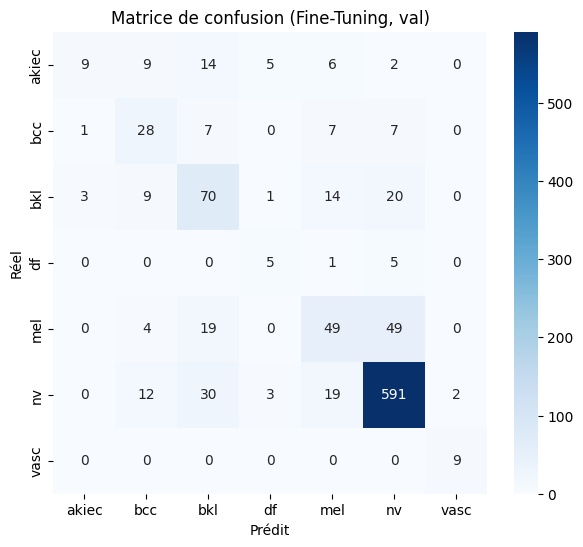

In [4]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_true = np.concatenate([y.numpy() for _, y in val_ds])
y_pred = np.argmax(model.predict(val_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion (Fine-Tuning, val)")
plt.show()

In [5]:
model.save("mobilenetv2_ft.keras")

from google.colab import files
files.download("mobilenetv2_ft.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>